# ML-Driven PVT Variation Aware Leakage Estimation
## Case: PMOS Transistor — OFF State | Neural Network (MLP) Regression

This notebook follows the workflow and evaluation style of the uploaded `Random_Forest.ipynb`, with the model family changed to **Neural Network (MLP) Regression**.

**Objective:** predict `id`, `ig`, `is`, and `ib` from the 12 input features in `pmos_off.csv`.

### Workflow
1. Setup and imports
2. Configure dataset and shared model paths
3. Load/inspect dataset and KCL check
4. Log-current target transformation
5. Fixed 70:15:15 train/validation/test split
6. Train four terminal-specific regressors
7. Evaluate validation and test metrics, including a clearly defined regression accuracy
8. Test-set parity plots and model-specific diagnostics
9. Save model files and metrics in `saved_models/pmos_off/`
10. Inference helper

A feed-forward multilayer perceptron learns nonlinear relationships. Inputs and log-targets are standardized for stable optimization; predictions are inverse-transformed back to log-current space.

In [1]:
# 1. Environment Setup & Imports
import os, json, time, joblib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Environment setup complete.")
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.neural_network import MLPRegressor

Environment setup complete.


In [2]:
# 2. Configuration & Paths
CASE_NAME = "pmos_off"
RANDOM_STATE = 42
EPSILON = 1e-20
REL_EPS = 1e-30

POSSIBLE_DATA_PATHS = [
    os.path.join("..", "Data_Generation_M1", "data", f"{CASE_NAME}.csv"),
    os.path.join("Data_Generation_M1", "data", f"{CASE_NAME}.csv"),
    os.path.join("..", "data", f"{CASE_NAME}.csv"),
    os.path.join("data", f"{CASE_NAME}.csv"),
    f"{CASE_NAME}.csv"
]
DATA_PATH = next((p for p in POSSIBLE_DATA_PATHS if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not locate {CASE_NAME}.csv. Current working directory: {os.getcwd()}\\n"
        f"Checked: {POSSIBLE_DATA_PATHS}. Place pmos_off.csv in a searched location or update POSSIBLE_DATA_PATHS."
    )

BASE_DIR = os.path.abspath(".")
SAVED_MODELS_DIR = os.path.join(BASE_DIR, "saved_models", CASE_NAME)
MODEL_FAMILY = "mlp"
PLOTS_DIR = os.path.join(BASE_DIR, "plots", CASE_NAME, MODEL_FAMILY)
os.makedirs(SAVED_MODELS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

FEATURE_COLS = ['vdd', 'temp', 'w', 'vd', 'vs', 'vg', 'vb',
                'vth0', 'toxe', 'ndep', 'u0', 'xj']
TARGET_COLS = ['id', 'ig', 'is', 'ib']

print("Dataset:", os.path.abspath(DATA_PATH))
print("Shared model directory:", SAVED_MODELS_DIR)
print("Model family:", MODEL_FAMILY)


Dataset: c:\Users\D Srivatsa\OneDrive\Desktop\DVD\model\pmos_off.csv
Shared model directory: c:\Users\D Srivatsa\OneDrive\Desktop\DVD\model\saved_models\pmos_off
Model family: mlp


In [3]:
# 3. Load and inspect dataset
df_raw = pd.read_csv(DATA_PATH)
df_raw.columns = [c.strip().lower() for c in df_raw.columns]
missing_required = [c for c in FEATURE_COLS + TARGET_COLS if c not in df_raw.columns]
if missing_required:
    raise ValueError(f"CSV is missing required columns: {missing_required}")

df_raw = df_raw[FEATURE_COLS + TARGET_COLS].copy()
print(f"Loaded {len(df_raw):,} rows.")
display(df_raw.head())
display(df_raw.isnull().sum().to_frame("missing_count"))

if df_raw.isnull().any().any():
    raise ValueError("Dataset contains missing values.")
if not np.isfinite(df_raw.to_numpy(dtype=float)).all():
    raise ValueError("Dataset contains NaN or infinite values.")

kcl_residual = np.abs(df_raw[TARGET_COLS].sum(axis=1))
print("\nKCL residual |Id + Ig + Is + Ib|:")
print(f"Maximum: {kcl_residual.max():.4e} A")
print(f"Mean   : {kcl_residual.mean():.4e} A")


Loaded 10,000 rows.


,vdd,temp,w,vd,vs,vg,vb,vth0,toxe,ndep,u0,xj,id,ig,is,ib
0,0.913164,24.063129,1.025305e-07,0.506903,0.231180,0.913164,0.913164,-0.261882,6.089308e-10,4.776073e+18,0.002158,6.728581e-09,-5.475815e-09,2.255745e-08,-1.708164e-08,9.967721e-15
1,0.905128,-27.568672,9.470522e-08,0.267233,0.619283,0.905128,0.905128,-0.229278,7.131976e-10,4.556488e+18,0.002329,7.701462e-09,-1.977087e-09,2.331804e-09,-3.547267e-10,1.000589e-14
2,0.947457,123.028750,4.280389e-08,0.400388,0.613323,0.947457,0.947457,-0.239289,6.114063e-10,4.774823e+18,0.002443,6.483357e-09,-3.496273e-09,4.744777e-09,-1.248518e-09,1.441555e-14
3,0.956105,43.014993,1.743946e-07,0.457499,0.599791,0.956105,0.956105,-0.238951,7.313812e-10,4.018635e+18,0.002094,7.057528e-09,-1.560451e-09,2.321704e-09,-7.612624e-10,9.978129e-15
4,0.901841,-14.311684,7.356811e-08,0.080543,0.796193,0.901841,0.901841,-0.261703,7.038829e-10,4.107926e+18,0.002410,7.214432e-09,-3.424054e-09,3.358158e-09,6.588464e-11,9.998946e-15


,missing_count
vdd,0
temp,0
w,0
vd,0
vs,0
vg,0
vb,0
vth0,0
toxe,0
ndep,0



KCL residual |Id + Ig + Is + Ib|:
Maximum: 7.5941e-15 A
Mean   : 5.5800e-16 A


## 4. Log-current target transformation

For each terminal, the model predicts:

\[
y_{\log}=\log_{10}(|I|+\epsilon),\quad \epsilon=10^{-20}\;\mathrm{A}
\]

The current sign is reconstructed using the **training partition only** (majority sign), not the true validation/test target. This matches the reference notebook approach. Mixed-sign terminal currents may need a separate sign classifier or a signed-target formulation.

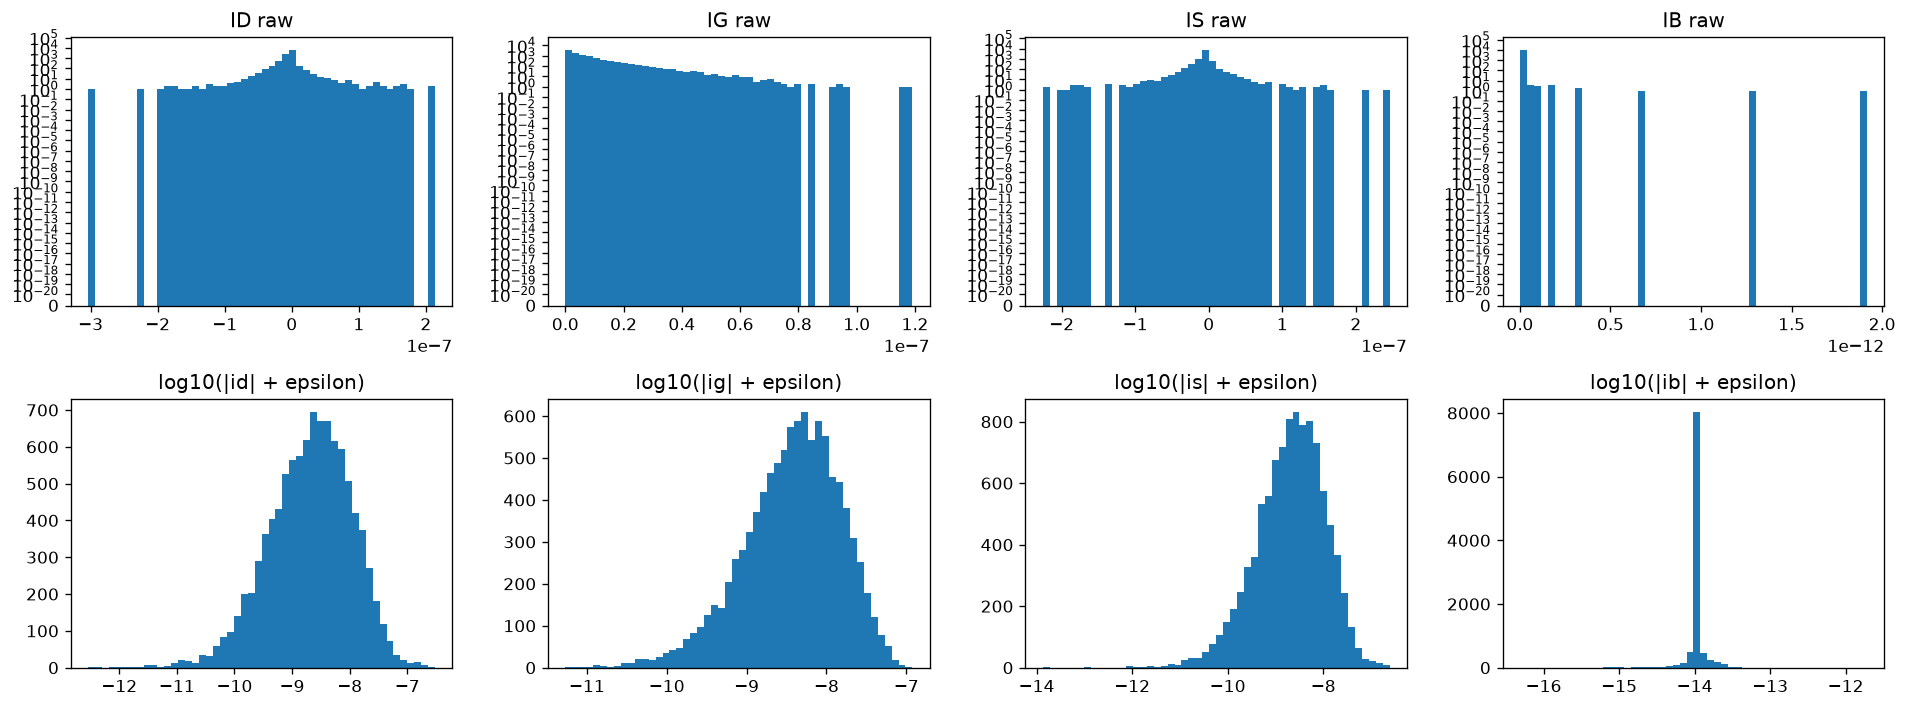

ID: positive=1363, negative=8637, zero=0
IG: positive=10000, negative=0, zero=0
IS: positive=1351, negative=8649, zero=0
IB: positive=10000, negative=0, zero=0


In [4]:
# 4. Log-current target transformation and distributions
df = df_raw.copy()
for col in TARGET_COLS:
    df[f"{col}_log"] = np.log10(np.abs(df[col].values) + EPSILON)
    signs = np.sign(df[col].values)
    signs[signs == 0] = 1
    df[f"{col}_sign"] = signs

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for j, col in enumerate(TARGET_COLS):
    axes[0, j].hist(df[col], bins=50)
    axes[0, j].set_title(f"{col.upper()} raw")
    axes[0, j].set_yscale("symlog", linthresh=EPSILON)
    axes[1, j].hist(df[f"{col}_log"], bins=50)
    axes[1, j].set_title(f"log10(|{col}| + epsilon)")
plt.tight_layout()
plt.show()

for col in TARGET_COLS:
    print(f"{col.upper()}: positive={(df[col]>0).sum()}, negative={(df[col]<0).sum()}, zero={(df[col]==0).sum()}")


In [5]:
# 5. Fixed 70:15:15 split
X = df[FEATURE_COLS].copy()
y_logs = df[[f"{c}_log" for c in TARGET_COLS]].copy()
y_raw = df[TARGET_COLS].copy()
y_signs = df[[f"{c}_sign" for c in TARGET_COLS]].copy()

X_train, X_temp, y_log_train, y_log_temp, y_raw_train, y_raw_temp, y_sign_train, y_sign_temp = train_test_split(
    X, y_logs, y_raw, y_signs, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)
X_val, X_test, y_log_val, y_log_test, y_raw_val, y_raw_test, y_sign_val, y_sign_test = train_test_split(
    X_temp, y_log_temp, y_raw_temp, y_sign_temp, test_size=0.50,
    random_state=RANDOM_STATE, shuffle=True
)

print(f"Train      : {len(X_train):,} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Validation : {len(X_val):,} ({len(X_val)/len(df)*100:.1f}%)")
print(f"Test       : {len(X_test):,} ({len(X_test)/len(df)*100:.1f}%)")

TRAIN_SIGN = {}
for target in TARGET_COLS:
    vals = y_sign_train[f"{target}_sign"].values
    TRAIN_SIGN[target] = 1 if np.sum(vals >= 0) >= np.sum(vals < 0) else -1
print("Training-majority signs:", TRAIN_SIGN)


Train      : 7,000 (70.0%)
Validation : 1,500 (15.0%)
Test       : 1,500 (15.0%)
Training-majority signs: {'id': -1, 'ig': 1, 'is': -1, 'ib': 1}


## 6. Neural Network (MLP) Regression

A feed-forward multilayer perceptron learns nonlinear relationships. Inputs and log-targets are standardized for stable optimization; predictions are inverse-transformed back to log-current space.

In [6]:
# 6. Train four MLP neural-network regressors
MODEL_TYPE = "MLPRegressor"
MODEL_PARAMS = {
    "hidden_layer_sizes": (128, 64, 32),
    "activation": "relu",
    "solver": "adam",
    "alpha": 1e-4,
    "batch_size": 256,
    "learning_rate_init": 1e-3,
    "max_iter": 500,
    "early_stopping": True,
    "validation_fraction": 0.15,
    "n_iter_no_change": 25,
    "tol": 1e-5,
    "random_state": RANDOM_STATE
}
trained_models = {}
training_summary = []
start_time = time.time()

for target in TARGET_COLS:
    base_pipeline = Pipeline([
        ("x_scaler", StandardScaler()),
        ("mlp", MLPRegressor(**MODEL_PARAMS))
    ])
    model = TransformedTargetRegressor(regressor=base_pipeline, transformer=StandardScaler())
    model.fit(X_train, y_log_train[f"{target}_log"])
    trained_models[target] = model
    train_r2 = r2_score(y_log_train[f"{target}_log"], model.predict(X_train))
    val_r2 = r2_score(y_log_val[f"{target}_log"], model.predict(X_val))
    mlp_fit = model.regressor_.named_steps["mlp"]
    training_summary.append({"Terminal": target.upper(), "Train R2 (log)": train_r2, "Validation R2 (log)": val_r2,
                             "Iterations": mlp_fit.n_iter_})
    print(f"{target.upper():>3}: trained | train R²={train_r2:.5f} | val R²={val_r2:.5f} | iterations={mlp_fit.n_iter_}")

print(f"\nTotal training time: {time.time()-start_time:.2f} seconds")
display(pd.DataFrame(training_summary))

 ID: trained | train R²=0.99079 | val R²=0.95793 | iterations=159
 IG: trained | train R²=0.99942 | val R²=0.99802 | iterations=199
 IS: trained | train R²=0.98310 | val R²=0.94237 | iterations=98
 IB: trained | train R²=0.94158 | val R²=0.71148 | iterations=138

Total training time: 36.75 seconds


,Terminal,Train R2 (log),Validation R2 (log),Iterations
0,ID,0.990793,0.957931,159
1,IG,0.999415,0.998022,199
2,IS,0.983104,0.942370,98
3,IB,0.941579,0.711478,138


In [7]:
# 7. Evaluation metrics (including regression accuracy)
def evaluate_models(models, X_eval, y_log_eval, y_raw_eval, split_name):
    rows, predictions = [], {}
    for target in TARGET_COLS:
        pred_log = models[target].predict(X_eval)
        pred_mag = 10.0 ** np.clip(pred_log, -300, 100)
        pred_raw = TRAIN_SIGN[target] * pred_mag
        actual_raw = y_raw_eval[target].to_numpy()
        actual_log = y_log_eval[f"{target}_log"].to_numpy()

        rel_err = np.abs(pred_raw - actual_raw) / np.maximum(np.abs(actual_raw), REL_EPS)
        within_10 = np.mean(rel_err <= 0.10) * 100
        rows.append({
            "Split": split_name,
            "Terminal": target.upper(),
            "Accuracy (within 10% error, %)": within_10,
            "R2 (Log Scale)": r2_score(actual_log, pred_log),
            "R2 (Linear Current)": r2_score(actual_raw, pred_raw),
            "Median Error (%)": np.median(rel_err) * 100,
            "95th Percentile Error (%)": np.percentile(rel_err, 95) * 100,
            "Mean Error (%)": np.mean(rel_err) * 100,
            "Within 5% (%)": np.mean(rel_err <= 0.05) * 100,
            "Within 10% (%)": within_10,
            "MAE (A)": mean_absolute_error(actual_raw, pred_raw),
            "RMSE (A)": np.sqrt(mean_squared_error(actual_raw, pred_raw))
        })
        predictions[target] = pred_raw
    return pd.DataFrame(rows), predictions

metrics_val, preds_val = evaluate_models(trained_models, X_val, y_log_val, y_raw_val, "Validation")
metrics_test, preds_test = evaluate_models(trained_models, X_test, y_log_test, y_raw_test, "Test")

print("Validation metrics:")
display(metrics_val.round(6))
print("Test metrics:")
display(metrics_test.round(6))


Validation metrics:


,Split,Terminal,"Accuracy (within 10% error, %)",R2 (Log Scale),R2 (Linear Current),Median Error (%),95th Percentile Error (%),Mean Error (%),Within 5% (%),Within 10% (%),MAE (A),RMSE (A)
0,Validation,ID,60.066667,0.957931,-0.507321,7.526926,210.227449,43.508615,37.866667,60.066667,0.0,0.0
1,Validation,IG,93.533333,0.998022,0.998092,2.916439,10.964273,4.090590,72.866667,93.533333,0.0,0.0
2,Validation,IS,49.666667,0.942370,-0.143912,10.077590,213.034706,62.361730,26.200000,49.666667,0.0,0.0
3,Validation,IB,90.933333,0.711478,0.831083,1.080897,18.482121,6.884517,84.333333,90.933333,0.0,0.0


Test metrics:


,Split,Terminal,"Accuracy (within 10% error, %)",R2 (Log Scale),R2 (Linear Current),Median Error (%),95th Percentile Error (%),Mean Error (%),Within 5% (%),Within 10% (%),MAE (A),RMSE (A)
0,Test,ID,58.200000,0.958943,0.341261,7.845585,203.009609,62.326256,36.333333,58.200000,0.0,0.0
1,Test,IG,93.133333,0.997871,0.998499,2.627238,11.953741,3.965872,76.000000,93.133333,0.0,0.0
2,Test,IS,51.800000,0.956604,-1.815445,9.503654,214.031050,57.566731,27.800000,51.800000,0.0,0.0
3,Test,IB,91.533333,0.512055,0.011955,1.055657,17.557504,5.629722,85.000000,91.533333,0.0,0.0


Saved: c:\Users\D Srivatsa\OneDrive\Desktop\DVD\model\plots\pmos_off\mlp\pmos_off_mlp_parity.png


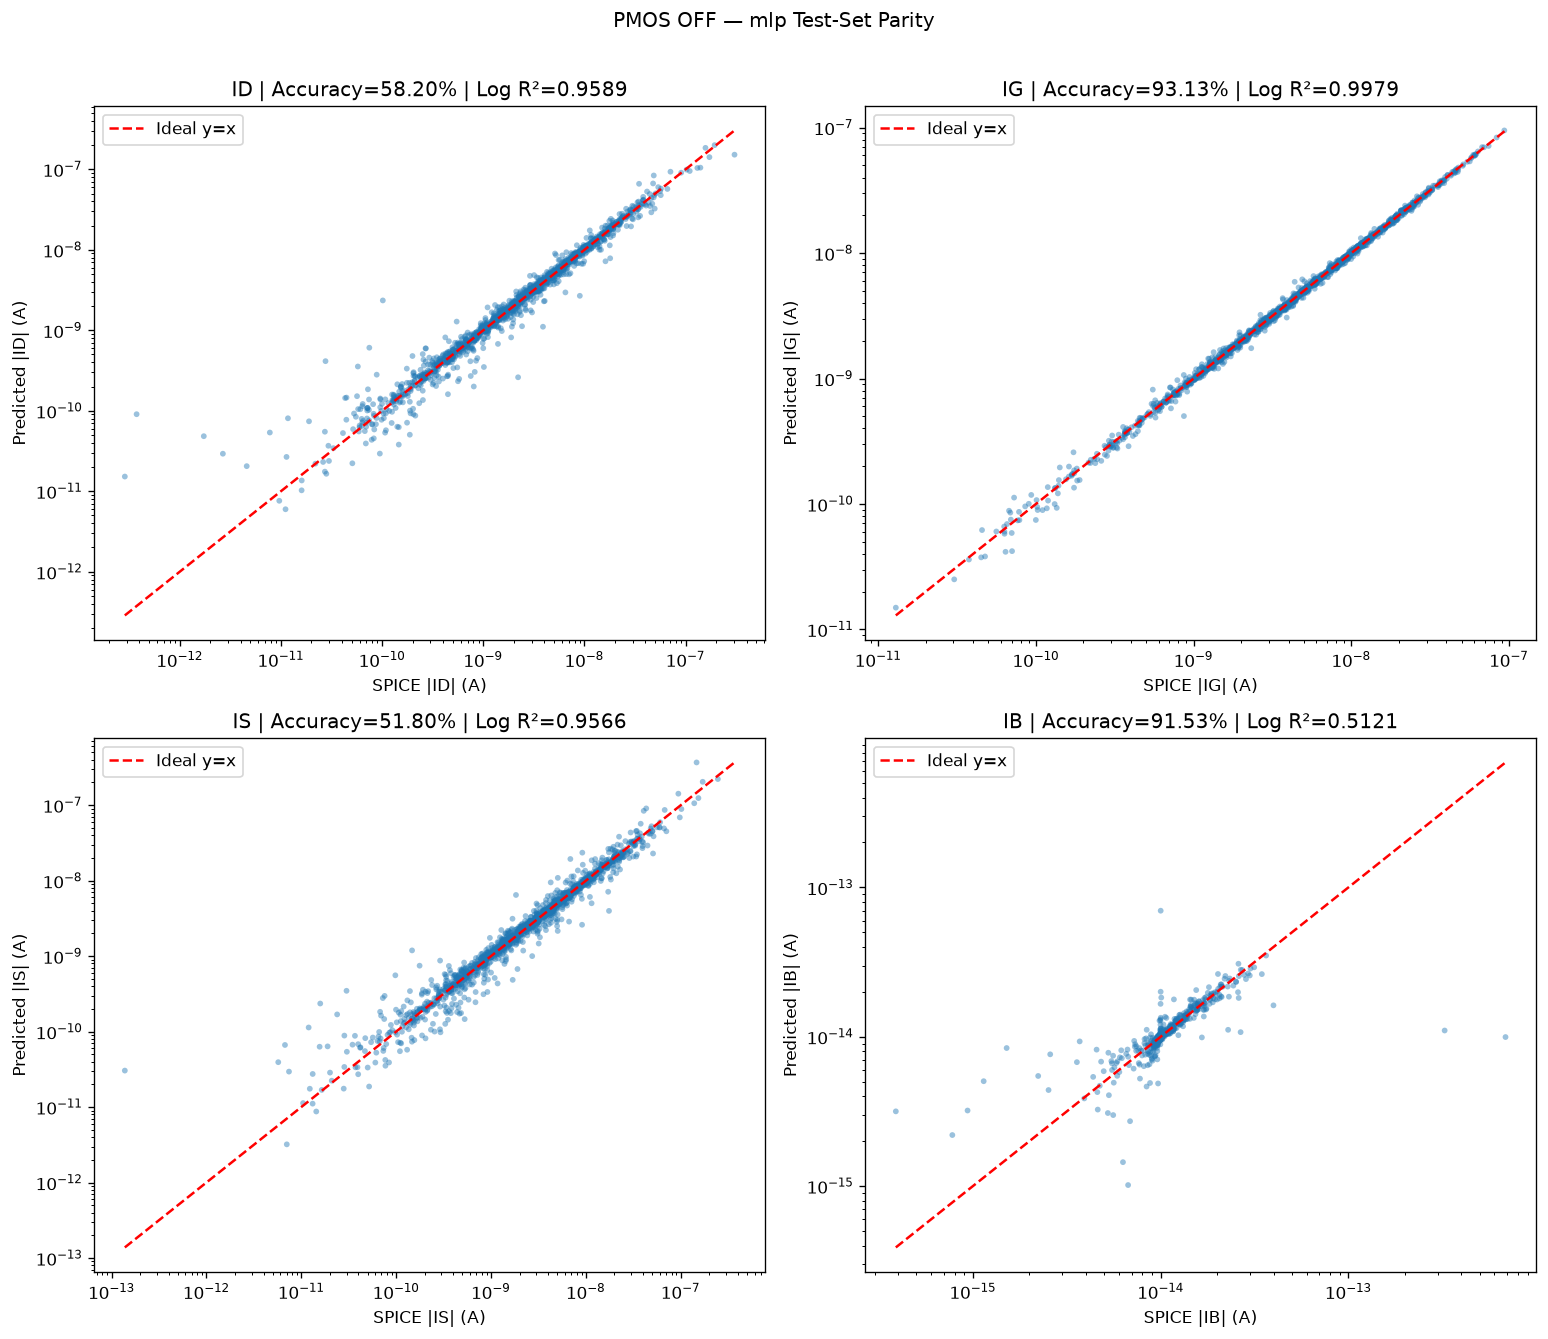

In [8]:
# 8. Test-set parity plots
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.flatten()

for idx, target in enumerate(TARGET_COLS):
    ax = axes[idx]
    y_true = np.maximum(np.abs(y_raw_test[target].to_numpy()), 1e-30)
    y_pred = np.maximum(np.abs(preds_test[target]), 1e-30)
    ax.scatter(y_true, y_pred, alpha=0.45, s=12, edgecolors="none")
    lo, hi = min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())
    ax.plot([lo, hi], [lo, hi], "r--", lw=1.5, label="Ideal y=x")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"SPICE |{target.upper()}| (A)")
    ax.set_ylabel(f"Predicted |{target.upper()}| (A)")
    row = metrics_test.loc[metrics_test["Terminal"] == target.upper()].iloc[0]
    ax.set_title(f"{target.upper()} | Accuracy={row['Accuracy (within 10% error, %)']:.2f}% | "
                 f"Log R²={row['R2 (Log Scale)']:.4f}")
    ax.legend()

plt.suptitle(f"PMOS OFF — {MODEL_FAMILY} Test-Set Parity", y=1.01)
plt.tight_layout()
parity_path = os.path.join(PLOTS_DIR, f"{CASE_NAME}_{MODEL_FAMILY}_parity.png")
plt.savefig(parity_path, dpi=200, bbox_inches="tight")
print("Saved:", parity_path)
plt.show()


Saved: c:\Users\D Srivatsa\OneDrive\Desktop\DVD\model\plots\pmos_off\mlp\pmos_off_mlp_training_loss.png


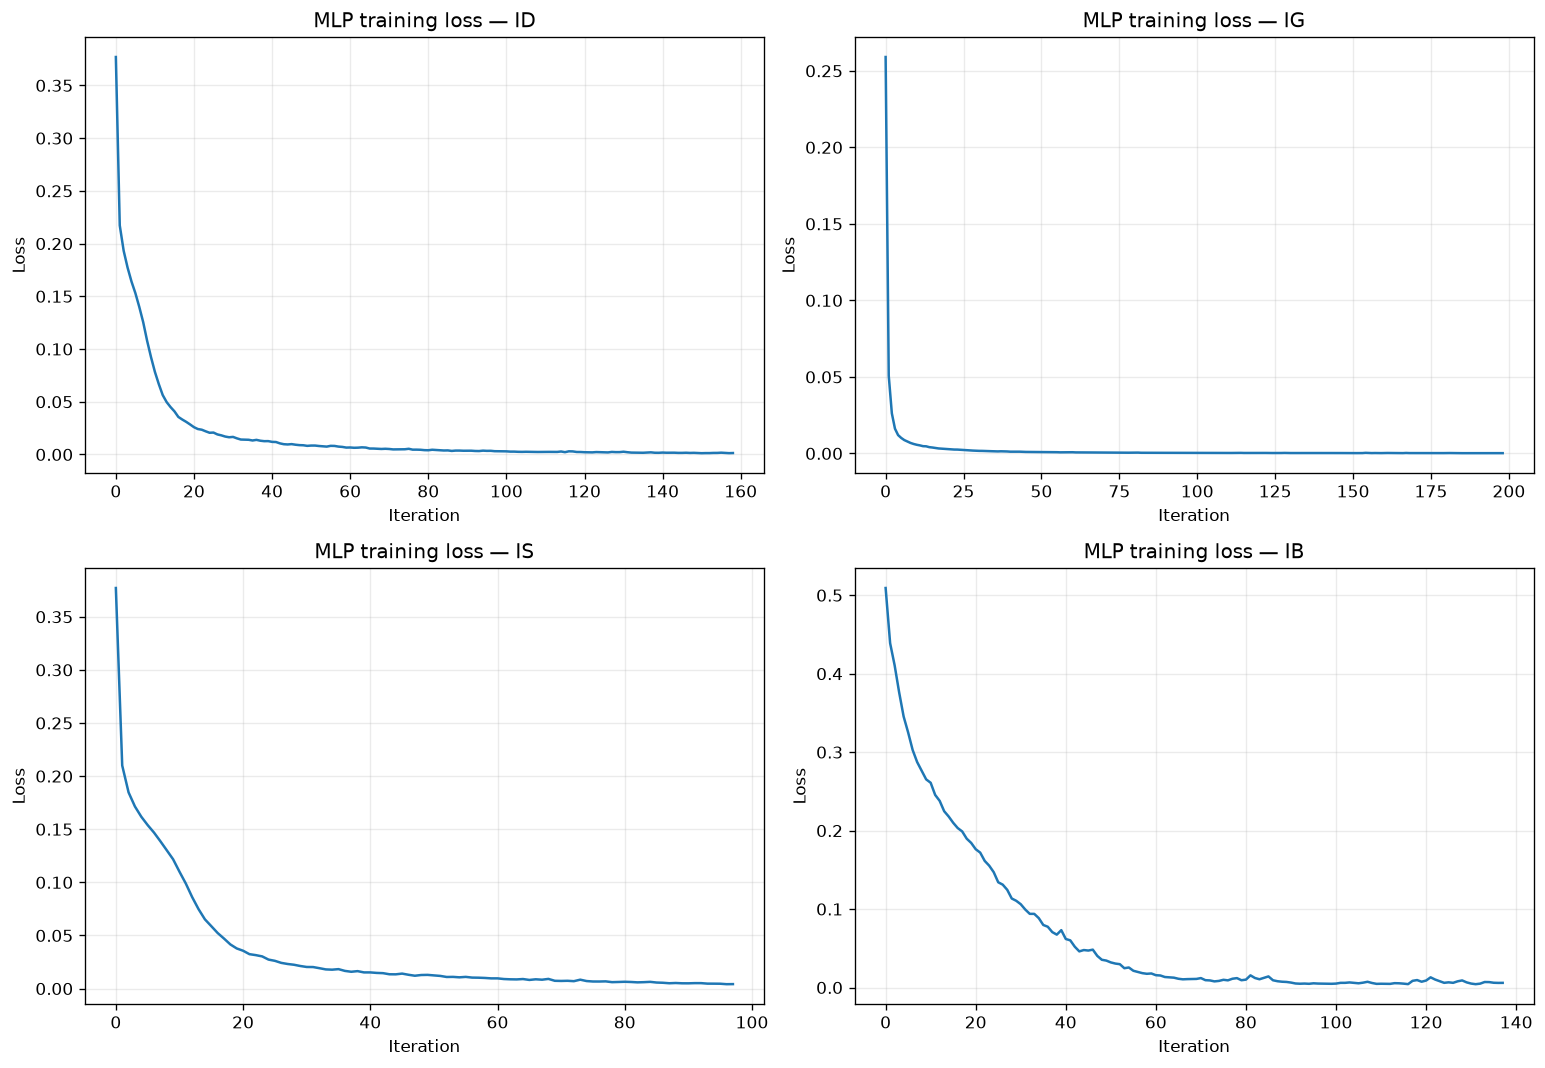

In [9]:
# 9. MLP training-loss curves
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()
for idx, target in enumerate(TARGET_COLS):
    fitted_mlp = trained_models[target].regressor_.named_steps["mlp"]
    axes[idx].plot(fitted_mlp.loss_curve_)
    axes[idx].set_title(f"MLP training loss — {target.upper()}")
    axes[idx].set_xlabel("Iteration")
    axes[idx].set_ylabel("Loss")
    axes[idx].grid(True, alpha=0.25)
plt.tight_layout()
loss_path = os.path.join(PLOTS_DIR, f"{CASE_NAME}_{MODEL_FAMILY}_training_loss.png")
plt.savefig(loss_path, dpi=200, bbox_inches="tight")
print("Saved:", loss_path)
plt.show()

In [10]:
# 10. Save models, metrics, and metadata in shared saved_models/pmos_off/
saved_files = {}
for target, model in trained_models.items():
    path = os.path.join(SAVED_MODELS_DIR, f"{MODEL_FAMILY}_{CASE_NAME}_{target}.joblib")
    joblib.dump(model, path)
    saved_files[target] = path
    print("Saved:", path)

metrics_val.to_csv(os.path.join(SAVED_MODELS_DIR, f"{MODEL_FAMILY}_{CASE_NAME}_validation_metrics.csv"), index=False)
metrics_test.to_csv(os.path.join(SAVED_MODELS_DIR, f"{MODEL_FAMILY}_{CASE_NAME}_test_metrics.csv"), index=False)

metadata = {
    "case_name": CASE_NAME,
    "model_type": MODEL_TYPE,
    "feature_columns": FEATURE_COLS,
    "target_columns": TARGET_COLS,
    "hyperparameters": MODEL_PARAMS,
    "epsilon": EPSILON,
    "relative_error_epsilon": REL_EPS,
    "random_state": RANDOM_STATE,
    "split": [0.70, 0.15, 0.15],
    "training_majority_sign": TRAIN_SIGN,
    "accuracy_definition": "percentage of samples with relative current error <= 10%",
    "validation_metrics": metrics_val.to_dict(orient="records"),
    "test_metrics": metrics_test.to_dict(orient="records"),
    "saved_models": saved_files,
    "created_at": time.strftime("%Y-%m-%d %H:%M:%S")
}
metadata_path = os.path.join(SAVED_MODELS_DIR, f"{MODEL_FAMILY}_{CASE_NAME}_metadata.json")
with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)
print("Saved metadata:", metadata_path)


Saved: c:\Users\D Srivatsa\OneDrive\Desktop\DVD\model\saved_models\pmos_off\mlp_pmos_off_id.joblib
Saved: c:\Users\D Srivatsa\OneDrive\Desktop\DVD\model\saved_models\pmos_off\mlp_pmos_off_ig.joblib
Saved: c:\Users\D Srivatsa\OneDrive\Desktop\DVD\model\saved_models\pmos_off\mlp_pmos_off_is.joblib
Saved: c:\Users\D Srivatsa\OneDrive\Desktop\DVD\model\saved_models\pmos_off\mlp_pmos_off_ib.joblib
Saved metadata: c:\Users\D Srivatsa\OneDrive\Desktop\DVD\model\saved_models\pmos_off\mlp_pmos_off_metadata.json


In [11]:
# 11. Inference helper
def predict_pmos_off_currents(pvt_sample_dict, model_dir=SAVED_MODELS_DIR):
    """Predict signed terminal currents (Id, Ig, Is, Ib), in amperes, for one sample."""
    input_df = pd.DataFrame([pvt_sample_dict])[FEATURE_COLS]
    predictions = {}
    for target in TARGET_COLS:
        model_path = os.path.join(model_dir, f"{MODEL_FAMILY}_{CASE_NAME}_{target}.joblib")
        model = joblib.load(model_path)
        pred_log = float(model.predict(input_df)[0])
        pred_mag = 10.0 ** np.clip(pred_log, -300, 100)
        predictions[target] = TRAIN_SIGN[target] * pred_mag
    return predictions

sample_query = X_test.iloc[0].to_dict()
sample_prediction = predict_pmos_off_currents(sample_query)
print("Input sample:")
display(pd.DataFrame([sample_query]))
print("Predicted terminal currents:")
for terminal, current in sample_prediction.items():
    print(f"{terminal.upper():>3}: {current:.6e} A")


Input sample:


,vdd,temp,w,vd,vs,vg,vb,vth0,toxe,ndep,u0,xj
0,0.854391,77.23103,1.299335e-07,0.013838,0.285654,0.854391,0.854391,-0.232169,6.488939e-10,4.428039e+18,0.002076,6.843709e-09


Predicted terminal currents:
 ID: -1.770263e-08 A
 IG: 2.383963e-08 A
 IS: -6.363468e-09 A
 IB: 1.018121e-14 A
